# Issue #360 — chronology-corrected low-N Top-2 selector data

This executed notebook profiles the corrected fixture-wide and M×3 10h panels. 2017–2021 are expanding OOF rows; 2022–2024 are exposed transfer rows generated by a model frozen through 2021. Registry year is authoritative, and every training label is available before the earliest target decision.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
repo = Path.cwd()
features = pd.read_parquet(repo / 'results/low_n_selector_data/features/selector_features.parquet')
cells = pd.read_parquet(repo / 'results/low_n_selector_data/features/selector_cells.parquet')
labels = pd.read_parquet(repo / 'results/low_n_selector_data/labels/selector_labels.parquet')
coverage = pd.read_csv(repo / 'results/low_n_selector_data/analysis/coverage.csv')
comparison = pd.read_csv(repo / 'results/low_n_selector_data/analysis/accepted_surface_comparison.csv')
freeze = json.loads((repo / 'results/low_n_selector_data/FREEZE_RECEIPT.json').read_text())
len(features), len(cells), len(labels), freeze['feature_frame_sha256'], freeze['cell_frame_sha256']

(132408,
 397224,
 132408,
 '2c410b7df2d512d6806055754ecd860a5fabda3ad482a8afb704cd109e57ee9c',
 'a3eb717c7f4e94649fae32249b16ea9d75b57865067de1b0f01c270d2e583c30')

## Chronology correction and exact cell grain

In [2]:
chronology = features.groupby('issue_year').agg(issues=('issue','nunique'), fixtures=('match_idx','size'), earliest_decision=('fixture_decision_ts','min'), latest_decision=('fixture_decision_ts','max'), training_label_max=('training_label_available_max_ts','max')).reset_index()
chronology['strict_time_order'] = chronology.training_label_max < chronology.earliest_decision
chronology

,issue_year,issues,fixtures,earliest_decision,latest_decision,training_label_max,strict_time_order
0,2017,47,16897,2016-12-31 06:00:00+00:00,2018-03-24 15:59:59+00:00,2016-12-31 04:29:59+00:00,True
1,2018,59,18490,2017-12-26 06:50:00+00:00,2019-04-03 16:44:59+00:00,2017-12-26 05:00:00+00:00,True
2,2019,55,17613,2018-12-31 06:00:00+00:00,2020-09-08 11:00:00+00:00,2018-12-31 05:00:00+00:00,True
3,2020,44,11947,2019-12-31 06:00:00+00:00,2021-04-28 12:00:00+00:00,2019-12-30 14:14:59+00:00,True
4,2021,58,18803,2020-12-31 06:05:00+00:00,2022-06-06 12:30:00+00:00,2020-12-31 06:00:00+00:00,True
5,2022,58,16740,2021-12-31 11:00:00+00:00,2023-04-05 07:00:00+00:00,2021-12-31 09:00:00+00:00,True
6,2023,55,15685,2022-12-30 06:45:00+00:00,2024-04-09 16:45:00+00:00,2021-12-31 09:00:00+00:00,True
7,2024,59,16233,2023-12-29 06:45:00+00:00,2024-12-30 18:15:00+00:00,2021-12-31 09:00:00+00:00,True


In [3]:
issue_routes = features[['issue','issue_year','issue_latest_kickoff_ts']].drop_duplicates('issue').copy()
issue_routes['legacy_latest_kickoff_year'] = pd.to_datetime(issue_routes.issue_latest_kickoff_ts, utc=True).dt.year
issue_routes['would_shift_under_legacy_rule'] = issue_routes.legacy_latest_kickoff_year.ne(issue_routes.issue_year)
route_summary = issue_routes.groupby('issue_year').agg(issues=('issue','size'), legacy_shifted_issues=('would_shift_under_legacy_rule','sum')).reset_index()
route_summary

,issue_year,issues,legacy_shifted_issues
0,2017,47,6
1,2018,59,6
2,2019,55,8
3,2020,44,14
4,2021,58,9
5,2022,58,5
6,2023,55,7
7,2024,59,0


In [4]:
counterexample = features.loc[features.issue.isin(['190804','190805']) & features.match_idx.eq(1), ['issue','issue_year','match_idx','fixture_kickoff_ts','fixture_decision_ts','issue_latest_kickoff_ts','train_year_max','training_label_available_max_ts']].sort_values('fixture_kickoff_ts')
assert counterexample.issue.tolist() == ['190804','190805']
assert counterexample.iloc[0].issue_latest_kickoff_ts.year == 2020
assert counterexample.iloc[0].issue_year == 2019
assert counterexample.iloc[0].train_year_max == 2018
counterexample

,issue,issue_year,match_idx,fixture_kickoff_ts,fixture_decision_ts,issue_latest_kickoff_ts,train_year_max,training_label_available_max_ts
45821,190804,2019,1,2019-08-20 21:00:00+00:00,2019-08-20 11:00:00+00:00,2020-01-30 03:29:59+00:00,2018,2018-12-31 05:00:00+00:00
46331,190805,2019,1,2019-08-27 19:30:00+00:00,2019-08-27 09:30:00+00:00,2019-09-17 02:44:59+00:00,2018,2018-12-31 05:00:00+00:00


In [5]:
assert len(cells) == 3 * len(features)
assert not cells.duplicated(['issue','match_idx','outcome_code']).any()
assert set(cells.outcome_code.astype(str)) == {'3','1','0'}
assert cells.groupby(['issue','match_idx']).size().eq(3).all()
assert (features.training_label_available_max_ts < features.fixture_decision_ts).all()
assert features.issue_date_source.eq('SOURCE_ISSUE_REGISTRY_YEAR').all()
assert features.selector_role.eq(features.prediction_role).all()
assert 'temporal_role' not in features.columns
'Chronology and M×3 identity checks passed.'

'Chronology and M×3 identity checks passed.'

## Coverage and completeness

In [6]:
coverage.assign(label_rate=lambda x: x.label_available / x.fixtures)

,issue_year,prediction_role,issues,fixtures,label_available,mean_books,mean_retained_mass,median_fixtures_per_issue,label_rate
0,2017,STRICTLY_PRIOR_EXPANDING_OOF,47,16897,16775,13.166953,0.740828,365.0,0.992780
1,2018,STRICTLY_PRIOR_EXPANDING_OOF,59,18490,18289,13.118172,0.741904,316.0,0.989129
2,2019,STRICTLY_PRIOR_EXPANDING_OOF,55,17613,17494,12.831147,0.741246,331.0,0.993244
3,2020,STRICTLY_PRIOR_EXPANDING_OOF,44,11947,11737,13.128317,0.740528,268.0,0.982422
4,2021,STRICTLY_PRIOR_EXPANDING_OOF,58,18803,18557,12.619635,0.737663,336.5,0.986917
5,2022,FROZEN_THROUGH_2021_TRANSFER,58,16740,16548,13.112186,0.738238,283.0,0.988530
6,2023,FROZEN_THROUGH_2021_TRANSFER,55,15685,15545,13.140453,0.741779,328.0,0.991074
7,2024,FROZEN_THROUGH_2021_TRANSFER,59,16233,16128,13.388961,0.742929,282.0,0.993532


In [7]:
missing = (features.isna().mean() * 100).sort_values(ascending=False).rename('missing_pct')
missing.to_frame().head(20)

,missing_pct
issue,0.0
issue_year,0.0
issue_anchor_ts,0.0
issue_latest_kickoff_ts,0.0
match_idx,0.0
fixture_kickoff_ts,0.0
fixture_decision_ts,0.0
training_label_available_max_ts,0.0
prediction_role,0.0
selector_role,0.0


## Top-2 calibration by year

In [8]:
panel = features.merge(labels[['issue','match_idx','label_available','top2_hit']], on=['issue','match_idx'], validate='one_to_one')
settled = panel[panel.label_available].copy()
settled['top2_hit_float'] = settled.top2_hit.astype(float)
annual = settled.groupby('issue_year').agg(issues=('issue','nunique'), fixtures=('match_idx','size'), mean_retained=('retained_mass','mean'), actual_top2=('top2_hit_float','mean'), mean_books=('n_available_books','mean')).reset_index()
annual['actual_minus_predicted'] = annual.actual_top2 - annual.mean_retained
annual

,issue_year,issues,fixtures,mean_retained,actual_top2,mean_books,actual_minus_predicted
0,2017,47,16775,0.740777,0.748614,13.168167,0.007837
1,2018,59,18289,0.741879,0.744382,13.124665,0.002503
2,2019,55,17494,0.741246,0.740654,12.839602,-0.000592
3,2020,44,11737,0.740332,0.747210,13.149868,0.006878
4,2021,58,18557,0.737660,0.741014,12.623538,0.003354
5,2022,58,16548,0.738197,0.734772,13.116328,-0.003425
6,2023,55,15545,0.741706,0.741332,13.147443,-0.000375
7,2024,59,16128,0.742909,0.743552,13.393291,0.000643


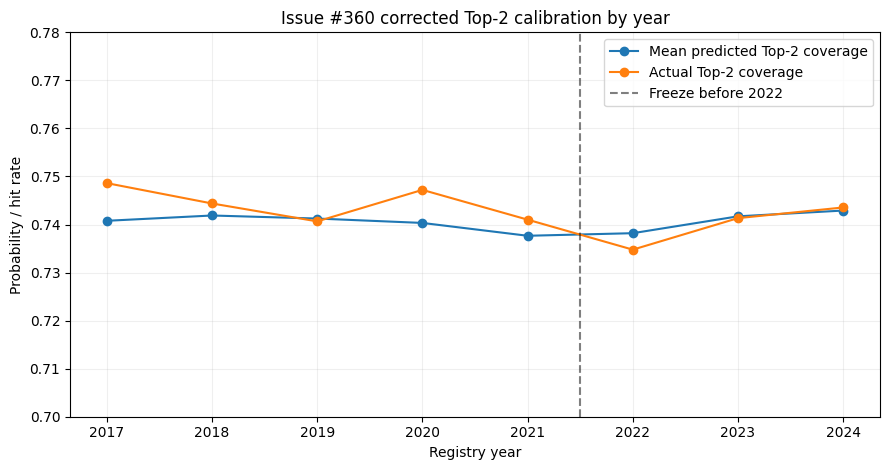

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(annual.issue_year, annual.mean_retained, marker='o', label='Mean predicted Top-2 coverage')
ax.plot(annual.issue_year, annual.actual_top2, marker='o', label='Actual Top-2 coverage')
ax.axvline(2021.5, color='black', linestyle='--', alpha=.5, label='Freeze before 2022')
ax.set(title='Issue #360 corrected Top-2 calibration by year', xlabel='Registry year', ylabel='Probability / hit rate', ylim=(.70,.78))
ax.grid(alpha=.2); ax.legend(); fig.tight_layout()
fig.savefig(repo / 'docs/research/figures/issue_360_top2_calibration.png', dpi=160)
plt.show()

## Probability distribution and calibration bins

In [10]:
settled['retained_bin'] = pd.cut(settled.retained_mass, bins=np.linspace(.45,1,12), include_lowest=True)
calibration = settled.groupby(['issue_year','retained_bin'], observed=True).agg(fixtures=('match_idx','size'), predicted=('retained_mass','mean'), actual=('top2_hit_float','mean')).reset_index()
calibration['residual'] = calibration.actual - calibration.predicted
calibration.head(20)

,issue_year,retained_bin,fixtures,predicted,actual,residual
0,2017,"(0.65, 0.7]",972,0.692710,0.702675,0.009964
1,2017,"(0.7, 0.75]",10512,0.727311,0.736682,0.009371
2,2017,"(0.75, 0.8]",4613,0.767761,0.771515,0.003754
3,2017,"(0.8, 0.85]",510,0.818628,0.849020,0.030392
4,2017,"(0.85, 0.9]",125,0.869216,0.808000,-0.061216
5,2017,"(0.9, 0.95]",36,0.919198,0.888889,-0.030309
6,2017,"(0.95, 1.0]",7,0.971974,0.857143,-0.114831
7,2018,"(0.65, 0.7]",1061,0.691759,0.685203,-0.006557
8,2018,"(0.7, 0.75]",11210,0.727627,0.731490,0.003863
9,2018,"(0.75, 0.8]",5152,0.767583,0.771351,0.003768


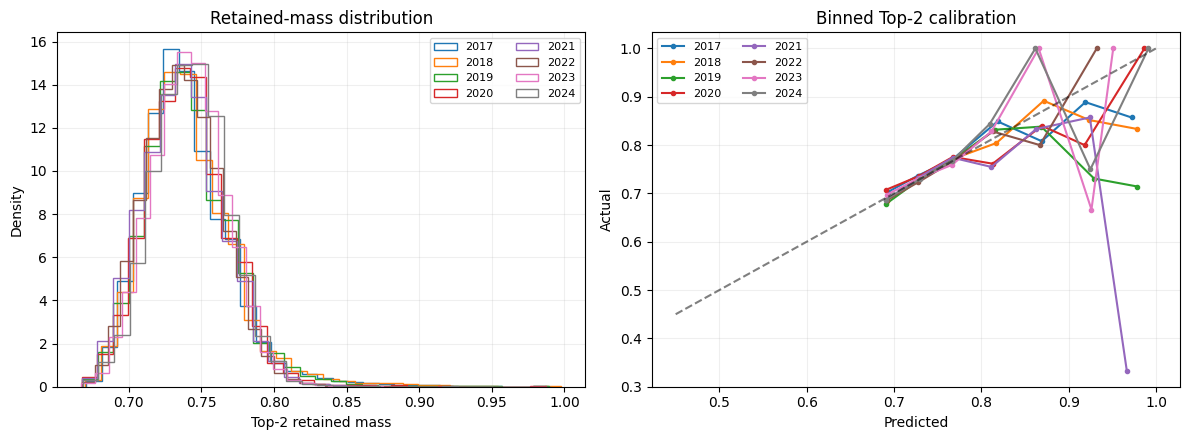

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for year, group in settled.groupby('issue_year'):
    axes[0].hist(group.retained_mass, bins=30, density=True, histtype='step', label=str(year))
for year, group in calibration.groupby('issue_year'):
    axes[1].plot(group.predicted, group.actual, marker='.', label=str(year))
axes[1].plot([.45,1],[.45,1], color='black', linestyle='--', alpha=.5)
axes[0].set(title='Retained-mass distribution', xlabel='Top-2 retained mass', ylabel='Density')
axes[1].set(title='Binned Top-2 calibration', xlabel='Predicted', ylabel='Actual')
axes[0].legend(ncol=2, fontsize=8); axes[1].legend(ncol=2, fontsize=8)
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(repo / 'docs/research/figures/issue_360_panel_profile.png', dpi=160)
plt.show()

## Accepted-source comparison and temporal assertions

In [12]:
comparison

,years,compared_cells,max_abs_delta_vs_candidate_diagnostic,exact_cells_vs_candidate_diagnostic,nonzero_cells,nonzero_max_abs_delta_vs_candidate_diagnostic,nonzero_exact_cells_vs_candidate_diagnostic,max_abs_delta_vs_accepted_q_eu_bjline,exact_cells_vs_accepted_q_eu_bjline,interpretation
0,2022-2024,145974,0.052628,0,58257,0.008818,0,0.008818,87717,chronology-corrected refit of the frozen archi...


In [13]:
assert set(features.issue_year) == set(range(2017, 2025))
assert (features.train_year_max < features.issue_year).all()
assert (features.training_label_available_max_ts < features.fixture_decision_ts).all()
assert set(features.loc[features.issue_year >= 2022, 'train_year_max']) == {2021}
assert set(features.loc[features.issue_year >= 2022, 'calibration_history_max_year']) == {2021}
assert not {'result_code','top2_hit','winning_sp','settlement_sp'} & set(features.columns)
assert features.isna().sum().sum() == 0
'All notebook assertions passed.'

'All notebook assertions passed.'

## Decision boundary

This notebook corrects #354's chronology, outcome grain and issue-unit coverage. It establishes data readiness only. It does not select S1–S3, inspect transfer-year performance to tune parameters, or authorize a betting candidate.